# Диагностика 7-дневной активации AI SaaS

Воспроизводимый стартовый анализ на полностью синтетических данных. Единое определение метрики хранится в `docs/metric_dictionary.md`, а SQL-реализация — в `sql/marts/001_mart_workspace_activation.sql`.

## tl;dr

- В выборке **592** eligible workspaces; 7-дневная активация — **32,3%**.
- В синтетическом эксперименте: control **29,7%**, treatment **39,9%**, разница **+10.2 п.п.**
- Эти числа демонстрируют аналитический метод и не являются результатами реальной компании.

## Context & Methods

**Решение:** определить главный провал onboarding funnel и проверить, связан ли guided onboarding с ростом активации. Единица анализа — workspace.

**Каноническая активация:** knowledge base подключена, teammate приглашён и не менее трёх AI-подсказок принято в течение 7 дней; первое принятие происходит после setup milestones.

Сравнение experiment variants ниже описательное: данные синтетические, а статистический вывод будет добавлен после проверки SRM и доверительных интервалов.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from ai_saas_analytics.data_quality import validate_dataset
from ai_saas_analytics.metrics import activation_records

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "generated"
plt.style.use("seaborn-v0_8-whitegrid")

## Data

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
quality = pd.DataFrame(
    [
        {"check": result.check_name, "failures": result.failure_count, "status": result.status}
        for result in validate_dataset(DATA_DIR)
    ]
)
assert quality["failures"].sum() == 0
display(pd.Series(manifest["counts"], name="rows").to_frame())
display(quality)

,rows
ai_suggestions,3592
experiment_assignments,365
product_events,12162
subscriptions,600
tickets,3592
users,927
workspaces,600


,check,failures,status
0,unique_workspace_id,0,PASS
1,unique_user_id,0,PASS
2,unique_event_id,0,PASS
3,unique_ticket_id,0,PASS
4,unique_suggestion_id,0,PASS
5,users_have_workspace,0,PASS
6,events_have_workspace,0,PASS
7,events_have_user,0,PASS
8,tickets_have_workspace_and_user,0,PASS
9,suggestions_have_parents,0,PASS


In [3]:
activation = pd.DataFrame(activation_records(DATA_DIR))
activation.head(3)

,workspace_id,created_at,acquisition_channel,country,team_size_bucket,seat_count,plan,subscription_status,knowledge_base_connected_at,teammate_invited_at,first_accepted_suggestion_at,accepted_suggestions_7d,experiment_variant,time_to_first_value_hours,activated_7d
0,ws_000001,2026-01-15 12:08:18+00:00,content,BY,2-5,2,growth,active,2026-01-17 21:17:12.290568+00:00,NaT,2026-01-19 11:15:06.416813+00:00,1,None,95.113449,False
1,ws_000003,2026-01-06 12:30:41+00:00,content,RU,6-20,6,starter,active,NaT,2026-01-06 15:02:06.791932+00:00,2026-01-31 08:09:43.069486+00:00,0,None,595.650575,False
2,ws_000004,2026-05-03 16:58:47+00:00,organic,RU,6-20,10,business,active,2026-05-05 09:45:52.793250+00:00,NaT,2026-05-06 08:39:21.018247+00:00,1,control,63.676116,False


## Results

In [4]:
funnel = pd.Series(
    {
        "Eligible workspaces": len(activation),
        "KB connected <7d": activation["knowledge_base_connected_at"].notna().sum(),
        "Teammate invited <7d": activation["teammate_invited_at"].notna().sum(),
        "3+ accepted suggestions <7d": activation["accepted_suggestions_7d"].ge(3).sum(),
        "Activated <7d": activation["activated_7d"].sum(),
    },
    name="workspaces",
).to_frame()
funnel["share_of_eligible"] = funnel["workspaces"] / len(activation)
funnel

,workspaces,share_of_eligible
Eligible workspaces,592,1.000000
KB connected <7d,434,0.733108
Teammate invited <7d,323,0.545608
3+ accepted suggestions <7d,211,0.356419
Activated <7d,191,0.322635


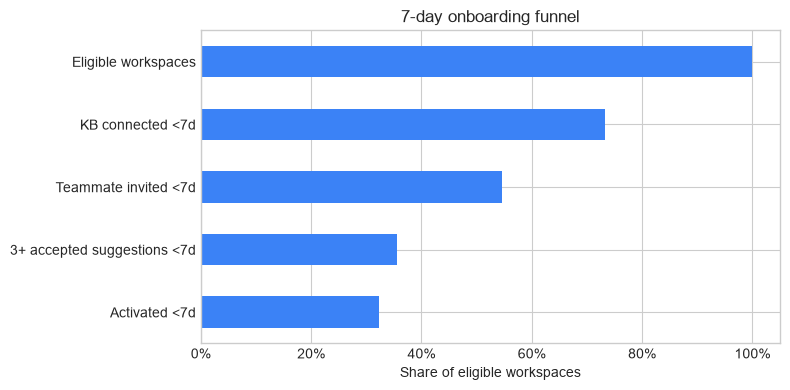

In [5]:
ax = funnel["share_of_eligible"].sort_values().plot.barh(figsize=(8, 4), color="#3B82F6")
ax.set(title="7-day onboarding funnel", xlabel="Share of eligible workspaces", ylabel="")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.tight_layout();

In [6]:
experiment = (
    activation.dropna(subset=["experiment_variant"])
    .groupby("experiment_variant")["activated_7d"]
    .agg(workspaces="size", activated="sum", activation_rate="mean")
)
experiment

,workspaces,activated,activation_rate
experiment_variant,,,
control,192,57,0.296875
treatment,173,69,0.398844


In [7]:
segments = (
    activation.groupby("acquisition_channel")["activated_7d"]
    .agg(workspaces="size", activation_rate="mean")
    .sort_values("activation_rate", ascending=False)
)
segments

,workspaces,activation_rate
acquisition_channel,,
organic,191,0.350785
partner,83,0.349398
content,123,0.308943
paid_search,113,0.300885
outbound,82,0.280488


## Takeaways

1. Baseline activation равна **32,3%** — это стартовая точка, а не KPI реальной компании.
2. В сгенерированном сценарии treatment выше control на **+10.2 п.п.**; перед продуктовым решением нужны SRM, доверительный интервал и guardrails.
3. Следующий аналитический шаг — локализовать выпадение между knowledge-base setup, teammate invite и первым принятием AI-подсказки, затем перенести проверенную витрину в DataLens.